# 01 · Контрольное сравнение PLCOm2012 и ML-моделей

**Контрольный сценарий:** `generate_baseline()` генерирует `y ~ Bernoulli(PLCOm2012(X))`. Поэтому PLCOm2012 является **оракулом условной вероятности** для данного синтетического сценария. Это не клиническая валидация и не эксперимент, доказывающий превосходство одной модели на реальных пациентах.

Общий протокол: [`docs/experiment_protocol.md`](../docs/experiment_protocol.md). Исследовательские гипотезы: [`docs/hypotheses.md`](../docs/hypotheses.md).

## 1. Среда и импорты

Запускаем ноутбук с ядром окружения `lung-cancer-ml`. Следующая ячейка ищет корень проекта независимо от того, запущен Jupyter из корня репозитория или из папки `notebooks`.

Если `xgboost` не установлен в выбранном окружении, нужно установить его **в это окружение**, а затем перезапустить ядро. Версии библиотек выводим для воспроизводимости.

In [9]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display, Markdown
from scipy.stats import binomtest
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

try:
    import xgboost
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError(
        "Для этого ноутбука требуется xgboost в текущем окружении. "
        "Активируйте lung-cancer-ml и установите пакет, затем перезапустите ядро."
    ) from exc

PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / 'src' / 'data_generation.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Не найден корень репозитория с src/data_generation.py')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_generation import generate_baseline
from src.evaluation import evaluate_binary, select_threshold_at_specificity
from src.plco import plco_risk
from src.preprocessing import FEATURE_COLUMNS, make_preprocessor, split_dataset

print('Корень проекта:', PROJECT_ROOT)
print('Python:', sys.version.split()[0], '|', sys.executable)
print('NumPy:', np.__version__, '| pandas:', pd.__version__)
print('SciPy:', scipy.__version__, '| scikit-learn:', sklearn.__version__)
print('XGBoost:', xgboost.__version__)

Корень проекта: /Users/dyadyundanil/Documents/lung-cancer-ml-study
Python: 3.11.11 | /opt/anaconda3/envs/lung-cancer-ml/bin/python
NumPy: 2.4.6 | pandas: 3.1.1
SciPy: 1.17.1 | scikit-learn: 1.9.1
XGBoost: 3.2.0


## 2. Параметры исследования и генерация данных

- **50 000** наблюдений: при распространённости положительного класса около 0,8% это даёт примерно 80 положительных случаев в test, а не ~17 при `n=10_000`.
- Разбиение **60/20/20** со стратификацией.
- Отдельные `DATA_SEED` и `SPLIT_SEED`.
- `risk`, `logit_base` и `logit_true` — технические столбцы генератора, **никогда не передаём их моделям**.

In [12]:
N = 50_000
DATA_SEED = 42
SPLIT_SEED = 123
MODEL_SEED = 123
MIN_SPECIFICITY = 0.90

baseline = generate_baseline(n=N, seed=DATA_SEED)
splits = split_dataset(
    baseline,
    val_fraction=0.20,
    test_fraction=0.20,
    seed=SPLIT_SEED,
)

assert list(splits.X_train.columns) == list(FEATURE_COLUMNS)
assert not {'risk', 'logit_base', 'logit_true', 'y'} & set(splits.X_train.columns)
assert set(splits.X_train.index).isdisjoint(splits.X_val.index)
assert set(splits.X_train.index).isdisjoint(splits.X_test.index)
assert set(splits.X_val.index).isdisjoint(splits.X_test.index)

split_overview = pd.DataFrame(
    {
        'Часть': ['Train', 'Validation', 'Test'],
        'Пациентов': [len(splits.y_train), len(splits.y_val), len(splits.y_test)],
        'Положительных': [splits.y_train.sum(), splits.y_val.sum(), splits.y_test.sum()],
        'Доля y=1, %': [
            100 * splits.y_train.mean(),
            100 * splits.y_val.mean(),
            100 * splits.y_test.mean(),
        ],
    }
)
print('Средний истинный риск, %:', round(100 * baseline['risk'].mean(), 3))
display(split_overview.round(3))
print('Используемые признаки:', list(FEATURE_COLUMNS))

Средний истинный риск, %: 0.824


,Часть,Пациентов,Положительных,"Доля y=1, %"
0,Train,30000,249,0.83
1,Validation,10000,83,0.83
2,Test,10000,83,0.83


Используемые признаки: ['age', 'bmi', 'education', 'cigs_per_day', 'smoking_years', 'quit_years', 'copd', 'personal_cancer', 'family_lung_cancer', 'is_current_smoker', 'race']


## 3. Модели и правила обучения

**PLCOm2012:** фиксированная опубликованная формула; обучения нет, применяем к исходным признакам без масштабирования.

**ML-модели:** каждая получает **отдельный `Pipeline(preprocessor, model)`**. Преобразование признаков (`StandardScaler`, `OneHotEncoder`) подгоняется только во время `fit(X_train, y_train)`. Все алгоритмы используют одни и те же наблюдения и доступные признаки.

Чтобы эксперимент быстро выполнялся на ноутбуке, для Random Forest, XGBoost и MLP заданы **фиксированные, умеренные по сложности настройки**. Это **не результаты оптимизации гиперпараметров** и не обязательно библиотечные значения по умолчанию. Специальный эксперимент H1 с честным подбором параметров будет проводиться отдельно.

`class_weight='balanced'` и `scale_pos_weight` здесь не включаем, поскольку они могут менять шкалу вероятностей и влиять на сравнение Brier score. Это также не означает, что такие методы нельзя исследовать позже.

Валидационная выборка **не используется при обучении моделей**; она понадобится для выбора порога. Для XGBoost в этом эксперименте не включаем early stopping по validation.

In [15]:
def build_pipeline(classifier):
    # Новый, ещё не обученный preprocessor для КАЖДОЙ модели.
    return Pipeline([
        ('preprocessor', make_preprocessor()),
        ('model', classifier),
    ])

models = {
    'Logistic Regression': build_pipeline(
        LogisticRegression(max_iter=1_000, random_state=MODEL_SEED)
    ),
    'Random Forest': build_pipeline(
        RandomForestClassifier(
            n_estimators=120,
            min_samples_leaf=8,
            n_jobs=4,
            random_state=MODEL_SEED,
        )
    ),
    'XGBoost': build_pipeline(
        XGBClassifier(
            n_estimators=200,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            objective='binary:logistic',
            eval_metric='logloss',
            tree_method='hist',
            n_jobs=4,
            random_state=MODEL_SEED,
        )
    ),
    'MLP': build_pipeline(
        MLPClassifier(
            hidden_layer_sizes=(32,),
            alpha=0.01,
            max_iter=180,
            early_stopping=False,
            random_state=MODEL_SEED,
        )
    ),
}
print('ML-модели:', ', '.join(models))

ML-модели: Logistic Regression, Random Forest, XGBoost, MLP


## 4. Обучение и предсказание вероятностей

ML-модели обучаем **только на train**. Для каждой сохраняем предсказания на validation и test, не выполняя здесь выбор порога. Для PLCOm2012 используем исходную формулу `plco_risk`.

В этой ячейке могут появиться предупреждения о сходимости MLP. Они не скрываются: их следует учитывать при интерпретации и позднее исследовать отдельно.

In [18]:
val_probabilities = {}
test_probabilities = {}
fit_seconds = {'PLCOm2012': 0.0}

# Оракул для контрольного сценария: без обучения.
val_probabilities['PLCOm2012'] = splits.X_val.apply(plco_risk, axis=1).to_numpy()
test_probabilities['PLCOm2012'] = splits.X_test.apply(plco_risk, axis=1).to_numpy()

for name, model in models.items():
    started = time.perf_counter()
    model.fit(splits.X_train, splits.y_train)
    fit_seconds[name] = time.perf_counter() - started
    val_probabilities[name] = model.predict_proba(splits.X_val)[:, 1]
    test_probabilities[name] = model.predict_proba(splits.X_test)[:, 1]
    print(f'{name}: обучение {fit_seconds[name]:.1f} с')

for name in val_probabilities:
    assert len(val_probabilities[name]) == len(splits.y_val)
    assert len(test_probabilities[name]) == len(splits.y_test)
    assert np.isfinite(val_probabilities[name]).all()
    assert np.isfinite(test_probabilities[name]).all()
    assert (np.asarray(val_probabilities[name]) >= 0).all()
    assert (np.asarray(val_probabilities[name]) <= 1).all()

print('Готово: для всех пяти подходов получены вероятности на validation и test.')

Logistic Regression: обучение 0.0 с
Random Forest: обучение 0.4 с
XGBoost: обучение 0.1 с
MLP: обучение 1.4 с
Готово: для всех пяти подходов получены вероятности на validation и test.


## 5. Выбор порогов **строго на validation**

Для каждой модели выбираем наименьший порог при правиле `p >= threshold`, обеспечивающий **Specificity(validation) ≥ 90%**. После выбора порога **не меняем его** на основании test.

Эта настройка порога **свойственна конкретной модели**; применять один числовой порог ко всем моделям было бы некорректно, поскольку шкалы их вероятностей различаются.

Низкая положительная распространённость делает оценку Recall нестабильной. Печатаем фактические количества TP, FN, FP, TN, а не только проценты.

In [21]:
thresholds = {}
validation_rows = []

for name, p_val in val_probabilities.items():
    threshold = select_threshold_at_specificity(
        splits.y_val,
        p_val,
        min_specificity=MIN_SPECIFICITY,
    )
    thresholds[name] = threshold
    metrics_val = evaluate_binary(splits.y_val, p_val, threshold=threshold)
    assert metrics_val['specificity'] >= MIN_SPECIFICITY - 1e-12
    validation_rows.append({
        'Модель': name,
        'Порог': threshold,
        'Specificity (val)': metrics_val['specificity'],
        'Recall (val)': metrics_val['recall'],
        'TP (val)': metrics_val['tp'],
        'FP (val)': metrics_val['fp'],
    })

validation_table = pd.DataFrame(validation_rows).set_index('Модель')
display(validation_table.round(5))

,Порог,Specificity (val),Recall (val),TP (val),FP (val)
Модель,,,,,
PLCOm2012,0.02225,0.90007,0.50602,42,991
Logistic Regression,0.01633,0.90007,0.50602,42,991
Random Forest,0.02387,0.90007,0.38554,32,991
XGBoost,0.02281,0.90007,0.49398,41,991
MLP,0.02155,0.90007,0.53012,44,991


**Краткий вывод (раздел 5).** Все модели достигли специфичности около **90,01% на validation** (по 991 FP), но выбранные пороги отличаются. Наибольший Recall на validation показала MLP (**53,0%; 44 из 83**), наименьший — Random Forest (**38,6%; 32 из 83**). Эти результаты не используются для подстройки моделей по test.


## 6. Независимая оценка на test

На test передаём пороги из предыдущей ячейки **без изменений**. Основная метрика — Recall при валидационно выбранном ограничении на Specificity. Помимо неё фиксируем фактическую test Specificity, ROC AUC, AP (не равно трапециевидной PR AUC), Brier score и стандартизованную partial ROC AUC при FPR ≤ 0,1.

**95%-е интервалы Уилсона для Recall** ниже отражают неопределённость, связанную с ограниченным числом положительных исходов в данной test-выборке. Они **не охватывают** вариацию из-за новой генерации данных или повторного обучения — это тема H4.

In [24]:
test_rows = []
for name, p_test in test_probabilities.items():
    m = evaluate_binary(splits.y_test, p_test, threshold=thresholds[name])
    recall_interval = binomtest(m['tp'], m['positives']).proportion_ci(
        confidence_level=0.95, method='wilson'
    )
    test_rows.append({
        'Модель': name,
        'Recall (test)': m['recall'],
        'Recall 95% CI': f'[{recall_interval.low:.3f}; {recall_interval.high:.3f}]',
        'Specificity (test)': m['specificity'],
        'ROC AUC': m['roc_auc'],
        'AP': m['average_precision'],
        'Brier': m['brier_score'],
        'pAUC std (FPR≤0.10)': m['pauc_standardized_fpr_0_10'],
        'TP': m['tp'],
        'FP': m['fp'],
        'FN': m['fn'],
        'TN': m['tn'],
        'Обучение, c': fit_seconds[name],
    })

test_table = pd.DataFrame(test_rows).set_index('Модель')
display(test_table.round(4))
print(f'Положительных исходов в test: {int(splits.y_test.sum())} из {len(splits.y_test)}')
print('Важно: значения Specificity(test) ниже 0.90 возможны без нарушения протокола.')

,Recall (test),Recall 95% CI,Specificity (test),ROC AUC,AP,Brier,pAUC std (FPR≤0.10),TP,FP,FN,TN,"Обучение, c"
Модель,,,,,,,,,,,,
PLCOm2012,0.5542,[0.447; 0.656],0.8981,0.8642,0.0672,0.0080,0.6686,46,1011,37,8906,0.0000
Logistic Regression,0.5301,[0.424; 0.634],0.8998,0.8186,0.0518,0.0081,0.6455,44,994,39,8923,0.0359
Random Forest,0.4699,[0.366; 0.576],0.9025,0.8156,0.0745,0.0080,0.6624,39,967,44,8950,0.4469
XGBoost,0.5783,[0.471; 0.679],0.8973,0.8603,0.0761,0.0080,0.6694,48,1018,35,8899,0.1151
MLP,0.5422,[0.436; 0.645],0.8948,0.8500,0.0774,0.0080,0.6588,45,1043,38,8874,1.3627


Положительных исходов в test: 83 из 10000
Важно: значения Specificity(test) ниже 0.90 возможны без нарушения протокола.


**Краткий вывод (раздел 6).** На test максимальный Recall получил XGBoost (**57,8%; 48 из 83**), тогда как PLCOm2012 выявила **46 из 83** (**55,4%**). При этом PLCOm2012 лидирует по ROC AUC (**0,8642**), а MLP — по AP (**0,0774**). Различия по Recall невелики при 83 положительных исходах; специфичность на test может быть ниже 90%, поскольку пороги фиксировались на validation.


## 7. ROC-кривые

Показываем кривые **всех пяти моделей на одной и той же test-выборке**. ROC AUC оценивает ранжирование рисков по всем возможным порогам, а основная клинически мотивированная метрика данного исследования — Recall при выбранном на validation пороге.

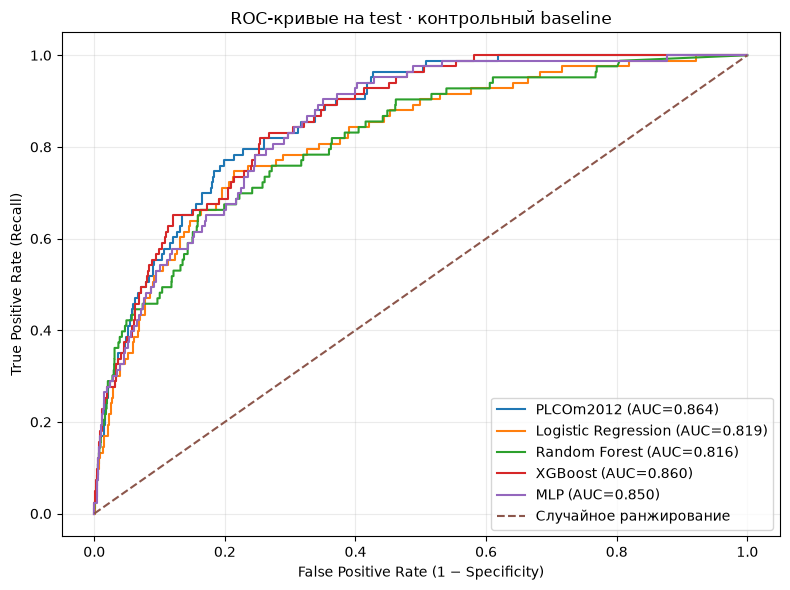

In [27]:
plt.figure(figsize=(8, 6))
for name, p_test in test_probabilities.items():
    fpr, tpr, _ = roc_curve(splits.y_test, p_test)
    auc = test_table.loc[name, 'ROC AUC']
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Случайное ранжирование')
plt.xlabel('False Positive Rate (1 − Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC-кривые на test · контрольный baseline')
plt.legend(loc='lower right')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 8. Precision–Recall-кривые

При редком положительном классе PR-кривые помогают увидеть обмен точности и полноты. Горизонтальная линия показывает частоту положительного класса в test; для случайного ранжирования ожидаемый AP связан с этой распространённостью.

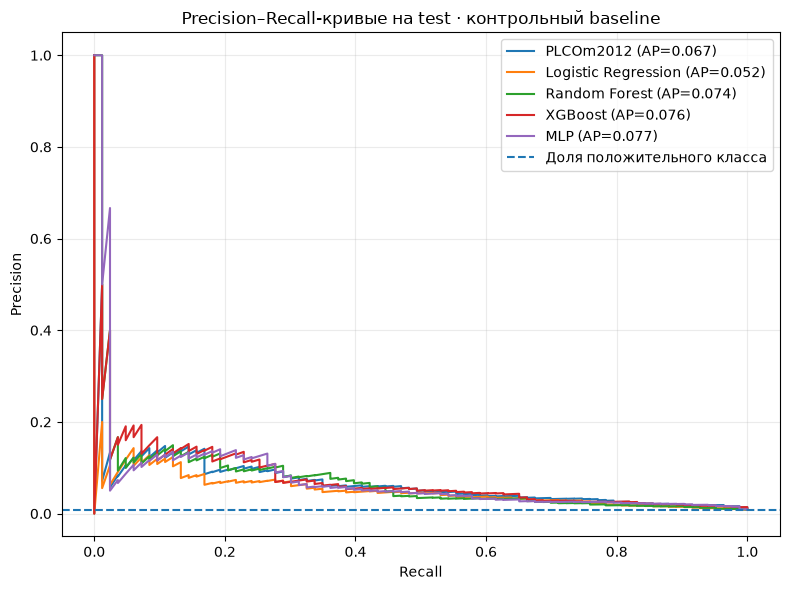

In [30]:
plt.figure(figsize=(8, 6))
for name, p_test in test_probabilities.items():
    precision, recall, _ = precision_recall_curve(splits.y_test, p_test)
    ap = test_table.loc[name, 'AP']
    plt.plot(recall, precision, label=f'{name} (AP={ap:.3f})')
plt.axhline(splits.y_test.mean(), linestyle='--', label='Доля положительного класса')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall-кривые на test · контрольный baseline')
plt.legend(loc='upper right')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Проверка и интерпретация

Важно разделять **оценку качества вероятностей** (Brier), **качество ранжирования** (ROC AUC, AP) и **чувствительность при конкретном пороге** (Recall). Поэтому не следует объявлять единственного «победителя» только по одному столбцу.

Мы можем сравнить средний Brier всех моделей с PLCOm2012 на конкретной выборке, но в контрольном сценарии в среднем по повторным независимым генерациям **истинные вероятности PLCOm2012 являются оптимальными для Brier score**. На одном случайном test отдельная обученная модель может показать чуть меньший Brier — это не опровержение такого свойства.

Данные сгенерированы искусственно и **не содержат внешней клинической валидации**. Ложноположительный прогноз риска (FP) не тождественен ложноположительному результату компьютерной томографии.

In [35]:
plco_brier = float(test_table.loc['PLCOm2012', 'Brier'])
comparison = pd.DataFrame({
    'Brier': test_table['Brier'],
    'Δ Brier относительно PLCO': test_table['Brier'] - plco_brier,
    'Recall (test)': test_table['Recall (test)'],
    'Specificity (test)': test_table['Specificity (test)'],
})
display(comparison.round(5))

plco_recall = float(test_table.loc['PLCOm2012', 'Recall (test)'])
plco_specificity = float(test_table.loc['PLCOm2012', 'Specificity (test)'])
display(Markdown(
    f'**Контрольный ориентир PLCOm2012:** Recall на test = {plco_recall:.1%}; '
    f'Specificity на test = {plco_specificity:.1%}. '
    'Оценки зависят от конкретной синтетической выборки и выбранного на validation порога.'
))

,Brier,Δ Brier относительно PLCO,Recall (test),Specificity (test)
Модель,,,,
PLCOm2012,0.00799,0.00000,0.55422,0.89805
Logistic Regression,0.00810,0.00011,0.53012,0.89977
Random Forest,0.00801,0.00002,0.46988,0.90249
XGBoost,0.00795,-0.00003,0.57831,0.89735
MLP,0.00799,0.00000,0.54217,0.89483


**Контрольный ориентир PLCOm2012:** Recall на test = 55.4%; Specificity на test = 89.8%. Оценки зависят от конкретной синтетической выборки и выбранного на validation порога.

**Краткий вывод (раздел 9).** Значения Brier score почти совпадают: **0,00799 у PLCOm2012** и **0,00795 у XGBoost** (разница около **−0,00003** с учётом округления). Небольшое преимущество XGBoost на одной выборке не доказывает лучшее восстановление истинных вероятностей: в этом контрольном сценарии их задаёт сама PLCOm2012.


## 10. Резюме и следующий шаг

**Что установлено в рамках первого эксперимента:**

1. Пять подходов оцениваются на одних и тех же пациентах и с одинаковым перечнем наблюдаемых признаков.
2. Предобработка ML-моделей обучается только на train; PLCOm2012 применяется к исходным признакам.
3. Порог каждой модели выбирается только на validation. Test используется для отчёта, а не для настройки.
4. Таблицы и графики позволяют сравнить алгоритмы в контрольном сценарии, где истинный механизм риска известен.

**Чего этот эксперимент не устанавливает:** что какая-либо ML-модель лучше PLCOm2012 на реальных пациентах; что различия устойчивы к смене случайной выборки; что конкретные гиперпараметры оптимальны.

**Далее:** отдельно изучить настройку гиперпараметров (H1), новые механизмы нелинейностей и взаимодействий (H2), влияние объёма данных (H3) и устойчивость к повторной генерации (H4). Структуру экспериментов определяем до просмотра их test-результатов.